## KMeans

(3000, 2) (3000,)


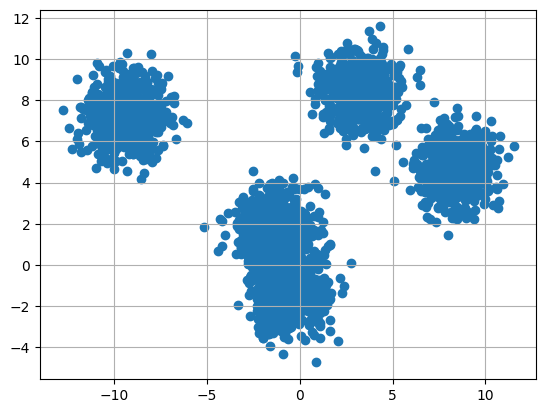

In [14]:
from sklearn.datasets import make_blobs

k = 5
X, y = make_blobs(n_samples=3000, centers=k, center_box=(-10.0, 10.0))
print(X.shape, y.shape)

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.scatter(X[:,0], X[:,1], marker="o")
plt.grid(True)
plt.show()

In [15]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=k, init="random", n_init=20, random_state=42) # default
y_pred = kmeans.fit_predict(X)
print(kmeans.labels_ is y_pred)
print(kmeans.cluster_centers_)
print(kmeans.inertia_, kmeans.score(X))

True
[[ 3.31114243  8.34305471]
 [-1.4383708   1.78993808]
 [-9.39837082  7.26519426]
 [-0.56315324 -1.41157433]
 [ 8.46167602  4.66835001]]
6024.464925035448 -6024.464925035447


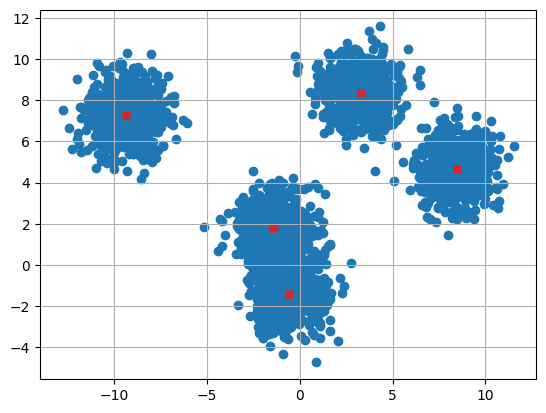

In [16]:
ax.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", color="C3")
fig

In [17]:
import numpy as np
X_new = np.array([[0, 2], [3, 2], [-7, 3], [-3, 15]])

print(kmeans.predict(X_new)) # hard clustering
print(kmeans.transform(X_new).round(2)) # soft clustering, distancia a cada centroide

[1 1 2 0]
[[ 7.16  1.45 10.77  3.46  8.87]
 [ 6.35  4.44 13.47  4.93  6.08]
 [11.61  5.69  4.89  7.8  15.55]
 [ 9.17 13.3  10.04 16.59 15.43]]


In [18]:
kmeans_optim = KMeans(n_clusters=k, init="k-means++", random_state=42) # default n_init=1
kmeans_optim.fit(X)

print(kmeans_optim.cluster_centers_)
print(kmeans_optim.inertia_)

[[ 3.31114243  8.34305471]
 [-9.39837082  7.26519426]
 [-0.55597696 -1.40674901]
 [-1.44721945  1.79039032]
 [ 8.46167602  4.66835001]]
6024.551819323961


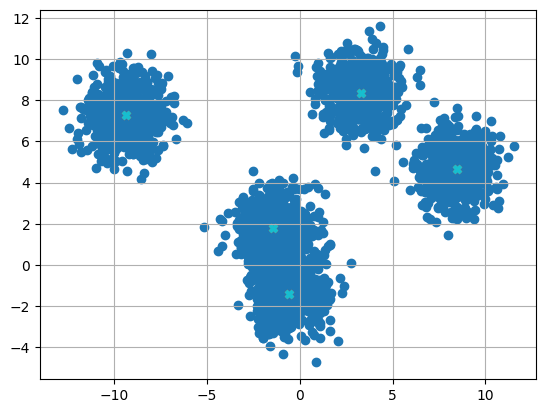

In [19]:
ax.scatter(kmeans_optim.cluster_centers_[:,0], kmeans_optim.cluster_centers_[:,1], marker="X", color="C9")
fig

In [20]:
from sklearn.cluster import MiniBatchKMeans
import numpy as np

n_batches = 200
mb_kmeans = MiniBatchKMeans(n_clusters=k, random_state=42)
for X_batch in np.array_split(X, n_batches):
    mb_kmeans.partial_fit(X_batch)

print(mb_kmeans.cluster_centers_)
print(mb_kmeans.inertia_)

[[ 3.31114243  8.34305471]
 [-9.39837082  7.26519426]
 [-0.56080818 -1.4520431 ]
 [ 8.46167602  4.66835001]
 [-1.41906162  1.75035721]]
29.218795119044835


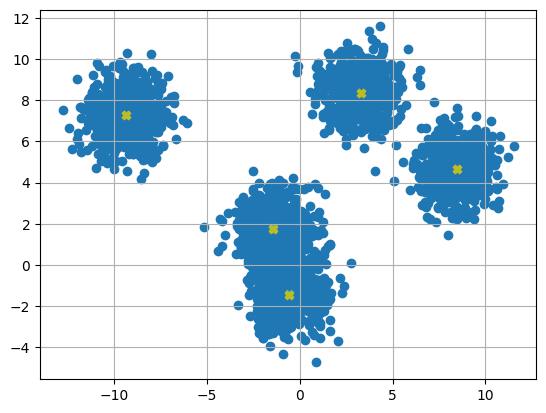

In [21]:
ax.scatter(mb_kmeans.cluster_centers_[:,0], mb_kmeans.cluster_centers_[:,1], marker="X", color="C8")
fig

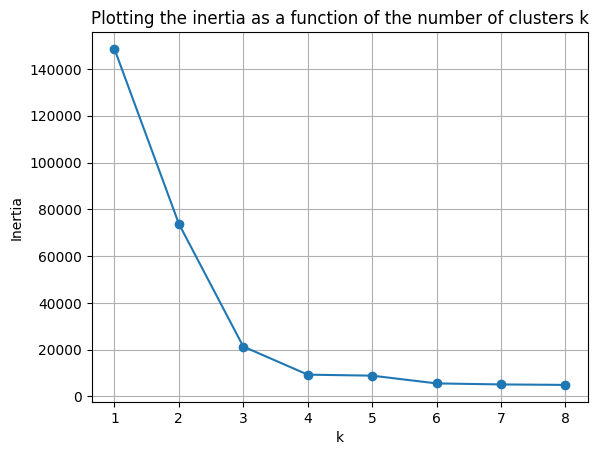

In [22]:
num_clusters = 8
inertia = []
for k in range(1,num_clusters+1):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    
fig2, ax2 = plt.subplots()
ax2.plot([k for k in range(1,num_clusters+1)], inertia, marker="o")
ax2.set_xlabel("k")
ax2.set_ylabel("Inertia")
ax2.set_title("Plotting the inertia as a function of the number of clusters k")
plt.grid(True)
plt.show()

In [23]:
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
print(silhouette_score(X, kmeans.labels_))

0.7341427708951241


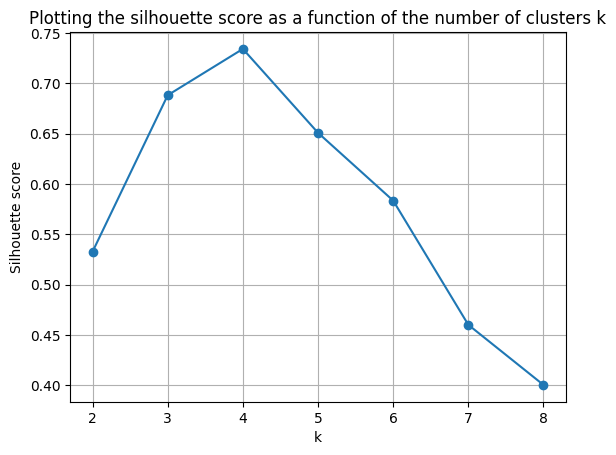

In [24]:
from sklearn.metrics import silhouette_score

num_clusters = 8
scores = []
for k in range(2,num_clusters+1): # silhouette_score es apartir de 2 clustes
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X)
    scores.append(silhouette_score(X, kmeans.labels_))

fig3, ax3 = plt.subplots()
ax3.plot([k for k in range(2,num_clusters+1)], scores, marker="o")
ax3.set_xlabel("k")
ax3.set_ylabel("Silhouette score")
ax3.set_title("Plotting the silhouette score as a function of the number of clusters k")
plt.grid(True)
plt.show()

## Density Based Spatial Clustering Application Noise

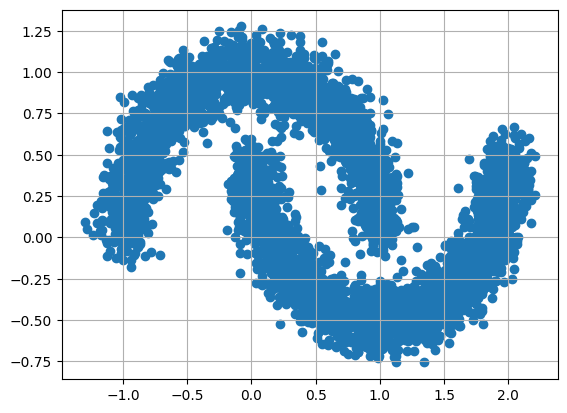

[ 0  1  1 ... -1  1  0]
6
[   0    1    2 ... 4996 4998 4999]


In [15]:
from sklearn.cluster import DBSCAN 
from sklearn.datasets import make_moons

X_moon, y_moon = make_moons(n_samples=5000, noise=0.1, random_state=42)

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots() 
ax.scatter(X_moon[:,0], X_moon[:,1], marker="o", color="C0")
plt.grid(True)
plt.show()

dbscan = DBSCAN(eps=0.045, min_samples=15)
dbscan.fit(X_moon)

# DBSACAN tiene metodo fit_predict() pero no predict() ni predict_proba()

labels = dbscan.labels_
print(labels) # las anomalias tiene etiqueta -1
print(len(np.unique(labels)))
print(dbscan.core_sample_indices_) # the indices of the core instances

[[-0.1196884   1.03684845]
 [ 0.03370055  0.2493631 ]
 [ 0.03864294  0.33033539]
 ...
 [ 0.85986767  0.60326185]
 [ 1.14571078 -0.44817941]
 [ 0.39745697  0.92398746]]


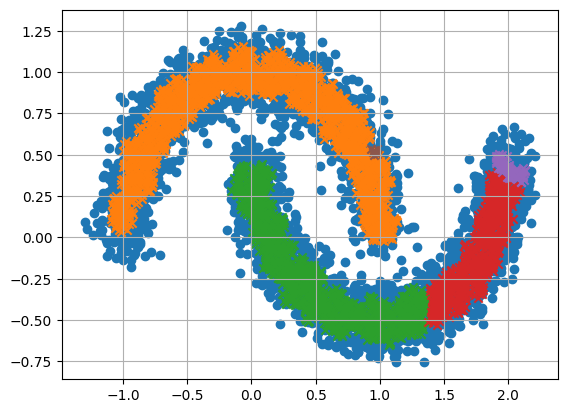

In [16]:
print(dbscan.components_) # the core instances themselves

for i in np.unique(labels)[1:]:
    X_i = X_moon[labels==i]
    ax.scatter(X_i[:,0], X_i[:,1], marker="x", color="C%s" %(i+1))
fig

## Gaussian Mixture Models

In [25]:
from sklearn.mixture import GaussianMixture

k = 5 # necesitas saberlo de antemano
gmm = GaussianMixture(n_components=k, n_init=10, random_state=42)
gmm.fit(X)

print(gmm.weights_)
print(gmm.means_)
print(gmm.covariances_)

[0.20282579 0.20012144 0.2        0.19987876 0.19717402]
[[-0.56648513 -1.36851921]
 [ 3.31395699  8.34275188]
 [-9.39837082  7.26519426]
 [ 8.46197991  4.66641969]
 [-1.43713152  1.75364298]]
[[[ 1.02040688  0.04612486]
  [ 0.04612486  1.01913404]]

 [[ 1.11460713 -0.05118015]
  [-0.05118015  1.01206269]]

 [[ 1.11620568 -0.00930918]
  [-0.00930918  1.07386139]]

 [[ 0.96188243  0.0423725 ]
  [ 0.0423725   1.01656534]]

 [[ 1.04551385  0.03288788]
  [ 0.03288788  0.92175789]]]


In [26]:
print(gmm.converged_)
print(gmm.n_iter_)

True
3


In [27]:
print(gmm.predict(X_new)) # hard assignment clustering
print(gmm.predict_proba(X_new)) # soft assignment clustering

[4 4 2 1]
[[9.46395249e-03 1.56780742e-11 5.87238694e-23 1.40099427e-17
  9.90536047e-01]
 [1.32657482e-01 1.95864348e-05 4.96228450e-32 1.09299720e-04
  8.67213632e-01]
 [2.26098110e-09 5.94453604e-24 9.92096896e-01 4.22050606e-50
  7.90310153e-03]
 [1.87421995e-43 9.99825704e-01 1.74295692e-04 5.22389294e-39
  2.06777646e-26]]


In [28]:
X_new, y_new = gmm.sample(3) # ES UN MODELO GENERATIVO !!!

print(X_new, y_new)

[[ 4.5302739   8.18311457]
 [ 3.42368457  9.38593687]
 [-8.90907468  6.60677659]] [1 1 2]


#### MNIST

In [29]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", as_frame=False)
X, y = mnist['data'], mnist['target']

In [30]:
X_train, X_test = X[:1_000], X[69_800:]
y_train, y_test = y[:1_000], y[69_800:]

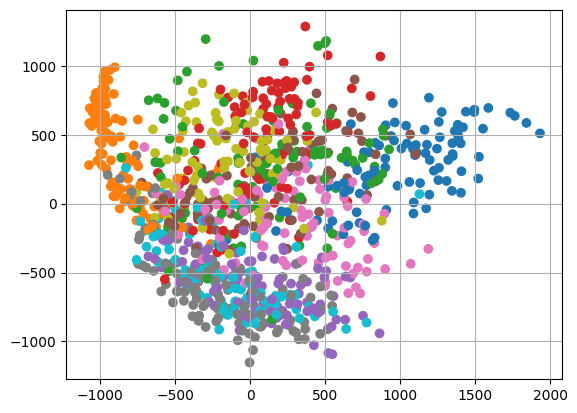

In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.scatter(X_pca[:, 0], X_pca[:, 1], color=["C%s" %(y) for y in y_train])
plt.grid(True)
plt.show()

In [32]:
gmm_mnist = GaussianMixture(n_components=len(np.unique(y_train)), n_init=10, random_state=42)
gmm_mnist.fit(X_train)

print(gmm_mnist.converged_)
print(gmm_mnist.n_iter_)

True
2


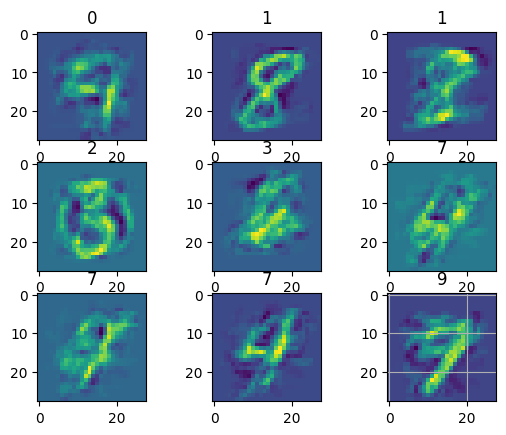

In [40]:
X_new, y_new = gmm_mnist.sample(9)

fig, axes = plt.subplots(3,3)
for i in range(3):
    for j in range(3):
        axes[i, j].imshow(X_new[3*i+j].reshape(28, 28))
        axes[i, j].set_title(y_new[3*i+j])
plt.grid(True)
plt.show()